In [ ]:
from pathlib import Path
import random
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import classification_report, confusion_matrix, balanced_accuracy_score
from sklearn.model_selection import train_test_split

ROOT = Path.cwd()
TRAIN_DIR = ROOT / "Train"
TEST_DIR = ROOT / "Test"
IMAGE_SIZE = (32, 32)
MAX_TRAIN_PER_CLASS = 500
MAX_TEST_PER_CLASS = 100
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

classes = sorted(path.name for path in TRAIN_DIR.iterdir() if path.is_dir())
print(f"Dataset: {ROOT}")
print(f"Classes ({len(classes)}): {classes}")


Dataset: c:\Users\sabar\Downloads\subhash
Classes (14): ['Abuse', 'Arrest', 'Arson', 'Assault', 'Burglary', 'Explosion', 'Fighting', 'NormalVideos', 'RoadAccidents', 'Robbery', 'Shooting', 'Shoplifting', 'Stealing', 'Vandalism']


In [ ]:
def sample_image_paths(root, class_names, limit_per_class):
    paths = []
    labels = []

    for class_name in class_names:
        class_paths = list((root / class_name).glob("*.png"))
        random.shuffle(class_paths)

        selected = class_paths[:limit_per_class]

        paths.extend(selected)
        labels.extend([class_name] * len(selected))

        print(
            f"{class_name}: selected "
            f"{len(selected)} / {len(class_paths)} frames"
        )

    return paths, labels


def load_images(paths, labels):
    features = np.empty(
        (len(paths), IMAGE_SIZE[0] * IMAGE_SIZE[1]),
        dtype=np.float32
    )

    for index, path in enumerate(paths):
        with Image.open(path) as image:
            image = image.convert("L").resize(IMAGE_SIZE)

            features[index] = (
                np.asarray(image, dtype=np.float32)
                .reshape(-1) / 255.0
            )

    return features, np.asarray(labels)


# Select images from each class
train_paths, train_labels = sample_image_paths(
    TRAIN_DIR,
    classes,
    MAX_TRAIN_PER_CLASS
)

# Load and preprocess images
X, y = load_images(train_paths, train_labels)

print(f"Total images loaded: {len(X):,}")

# Split the dataset into training and validation sets
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=SEED,
    stratify=y
)

# Display the dataset sizes
print(
    f"Training frames: {len(X_train):,}; "
    f"validation frames: {len(X_valid):,}"
)

Abuse: selected 500 / 19076 frames
Arrest: selected 500 / 26397 frames
Arson: selected 500 / 24421 frames
Assault: selected 500 / 10360 frames
Burglary: selected 500 / 39504 frames
Explosion: selected 500 / 18753 frames
Fighting: selected 500 / 24684 frames
NormalVideos: selected 500 / 947768 frames
RoadAccidents: selected 500 / 23486 frames
Robbery: selected 500 / 41493 frames
Shooting: selected 500 / 7140 frames
Shoplifting: selected 500 / 24835 frames
Stealing: selected 500 / 44802 frames
Vandalism: selected 500 / 13626 frames
Total images loaded: 7,000
Training frames: 5,600; validation frames: 1,400


In [ ]:
model = SGDClassifier(
    loss="log_loss",
    penalty="l2",
    alpha=1e-4,
    max_iter=30,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=5,
    random_state=SEED,
)
model.fit(X_train, y_train)

valid_predictions = model.predict(X_valid)
print(f"Validation balanced accuracy: {balanced_accuracy_score(y_valid, valid_predictions):.3f}")
print(classification_report(y_valid, valid_predictions, labels=classes, zero_division=0))


Validation balanced accuracy: 0.656
               precision    recall  f1-score   support

        Abuse       1.00      0.29      0.45       100
       Arrest       0.97      0.66      0.79       100
        Arson       0.50      0.80      0.62       100
      Assault       0.61      0.72      0.66       100
     Burglary       0.89      0.64      0.74       100
    Explosion       0.96      0.75      0.84       100
     Fighting       0.88      0.59      0.71       100
 NormalVideos       0.71      0.55      0.62       100
RoadAccidents       0.86      0.24      0.38       100
      Robbery       0.34      0.69      0.46       100
     Shooting       0.47      0.94      0.63       100
  Shoplifting       0.98      0.85      0.91       100
     Stealing       0.63      0.64      0.64       100
    Vandalism       0.71      0.82      0.76       100

     accuracy                           0.66      1400
    macro avg       0.75      0.66      0.66      1400
 weighted avg       0.75   

In [ ]:
test_paths, test_labels = sample_image_paths(TEST_DIR, classes, MAX_TEST_PER_CLASS)
X_test, y_test = load_images(test_paths, test_labels)
test_predictions = model.predict(X_test)

print(f"Test balanced accuracy: {balanced_accuracy_score(y_test, test_predictions):.3f}")
print(classification_report(y_test, test_predictions, labels=classes, zero_division=0))

cm = confusion_matrix(y_test, test_predictions, labels=classes)
cm_table = pd.DataFrame(cm, index=classes, columns=classes)
cm_table


Abuse: selected 100 / 297 frames
Arrest: selected 100 / 3365 frames
Arson: selected 100 / 2793 frames
Assault: selected 100 / 2657 frames
Burglary: selected 100 / 7657 frames
Explosion: selected 100 / 6510 frames
Fighting: selected 100 / 1231 frames
NormalVideos: selected 100 / 64952 frames
RoadAccidents: selected 100 / 2663 frames
Robbery: selected 100 / 835 frames
Shooting: selected 100 / 7630 frames
Shoplifting: selected 100 / 7623 frames
Stealing: selected 100 / 1984 frames
Vandalism: selected 100 / 1111 frames
Test balanced accuracy: 0.071
               precision    recall  f1-score   support

        Abuse       0.00      0.00      0.00       100
       Arrest       0.00      0.00      0.00       100
        Arson       0.11      0.19      0.14       100
      Assault       0.03      0.02      0.02       100
     Burglary       0.03      0.01      0.02       100
    Explosion       0.20      0.01      0.02       100
     Fighting       0.03      0.01      0.02       100
 NormalV

,Abuse,Arrest,Arson,Assault,Burglary,Explosion,Fighting,NormalVideos,RoadAccidents,Robbery,Shooting,Shoplifting,Stealing,Vandalism
Abuse,0,0,0,0,0,0,0,0,0,52,48,0,0,0
Arrest,0,0,4,8,0,0,0,1,2,48,15,0,12,10
Arson,6,0,19,4,1,0,4,9,1,31,6,0,0,19
Assault,0,0,2,2,0,0,0,1,2,33,60,0,0,0
Burglary,0,0,51,0,1,0,0,0,0,18,9,0,3,18
Explosion,2,0,9,9,0,1,1,9,0,24,15,0,25,5
Fighting,0,1,16,8,0,0,1,8,0,39,13,0,1,13
NormalVideos,0,0,12,3,1,2,5,9,1,35,20,0,2,10
RoadAccidents,0,0,5,1,4,0,1,6,0,56,18,0,7,2
Robbery,0,0,0,0,11,0,9,11,2,30,19,0,15,3


In [ ]:
import joblib

MODEL_PATH = ROOT / "dcsass_frame_classifier.joblib"
joblib.dump({"model": model, "classes": classes, "image_size": IMAGE_SIZE}, MODEL_PATH)
print(f"Saved model to: {MODEL_PATH}")


def predict_frame(image_path):
    with Image.open(image_path) as image:
        image = image.convert("L").resize(IMAGE_SIZE)
        features = np.asarray(image, dtype=np.float32).reshape(1, -1) / 255.0
    prediction = model.predict(features)[0]
    confidence = float(model.predict_proba(features).max())
    return prediction, confidence

example_path = test_paths[0]
print(f"Example: {example_path.name} -> {predict_frame(example_path)}")


Saved model to: c:\Users\sabar\Downloads\subhash\dcsass_frame_classifier.joblib
Example: Abuse028_x264_910.png -> (np.str_('Shooting'), 0.9990615248680115)


In [ ]:
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 64
EPOCHS = 8

class FrameDataset(Dataset):
    def __init__(self, paths, labels, class_to_index, transform):
        self.paths = paths
        self.labels = labels
        self.class_to_index = class_to_index
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        with Image.open(self.paths[index]) as image:
            image = image.convert("RGB")
        return self.transform(image), self.class_to_index[self.labels[index]]

class SmallCNN(nn.Module):
    def __init__(self, number_of_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1)),
        )
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(0.3), nn.Linear(128, number_of_classes))

    def forward(self, inputs):
        return self.classifier(self.features(inputs))

class_to_index = {class_name: index for index, class_name in enumerate(classes)}
train_frame_paths, valid_frame_paths, train_frame_labels, valid_frame_labels = train_test_split(
    train_paths, train_labels, test_size=0.2, random_state=SEED, stratify=train_labels
)

train_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize([0.5] * 3, [0.5] * 3),
])
valid_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize([0.5] * 3, [0.5] * 3),
])

train_loader = DataLoader(FrameDataset(train_frame_paths, train_frame_labels, class_to_index, train_transform), batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
valid_loader = DataLoader(FrameDataset(valid_frame_paths, valid_frame_labels, class_to_index, valid_transform), batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

def evaluate_loader(network, loader):
    network.eval()
    correct = total = 0
    with torch.no_grad():
        for images, labels in loader:
            outputs = network(images.to(DEVICE))
            correct += (outputs.argmax(1).cpu() == labels).sum().item()
            total += labels.size(0)
    return correct / total

cnn = SmallCNN(len(classes)).to(DEVICE)
optimizer = torch.optim.AdamW(cnn.parameters(), lr=1e-3, weight_decay=1e-4)
criterion = nn.CrossEntropyLoss()

for epoch in range(EPOCHS):
    cnn.train()
    running_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        loss = criterion(cnn(images), labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * labels.size(0)
    validation_accuracy = evaluate_loader(cnn, valid_loader)
    print(f"Epoch {epoch + 1}/{EPOCHS} - loss: {running_loss / len(train_loader.dataset):.4f} - validation accuracy: {validation_accuracy:.3f}")

print(f"Training device: {DEVICE}")


Epoch 1/8 - loss: 2.3733 - validation accuracy: 0.254
Epoch 2/8 - loss: 2.1515 - validation accuracy: 0.366
Epoch 3/8 - loss: 2.0223 - validation accuracy: 0.387
Epoch 4/8 - loss: 1.9036 - validation accuracy: 0.336
Epoch 5/8 - loss: 1.8306 - validation accuracy: 0.422
Epoch 6/8 - loss: 1.7304 - validation accuracy: 0.464
Epoch 7/8 - loss: 1.6590 - validation accuracy: 0.484
Epoch 8/8 - loss: 1.6156 - validation accuracy: 0.463
Training device: cpu


In [ ]:
test_paths, test_labels = sample_image_paths(TEST_DIR, classes, MAX_TEST_PER_CLASS)
test_loader = DataLoader(FrameDataset(test_paths, test_labels, class_to_index, valid_transform), batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

def predict_loader(network, loader):
    network.eval()
    predictions, actual = [], []
    with torch.no_grad():
        for images, labels in loader:
            predictions.extend(network(images.to(DEVICE)).argmax(1).cpu().numpy())
            actual.extend(labels.numpy())
    return np.asarray(actual), np.asarray(predictions)

y_test_indices, test_predictions_indices = predict_loader(cnn, test_loader)
test_accuracy = (y_test_indices == test_predictions_indices).mean()
print(f"Held-out test accuracy: {test_accuracy:.3f}")
print(classification_report(y_test_indices, test_predictions_indices, target_names=classes, zero_division=0))

torch.save({"model_state": cnn.state_dict(), "classes": classes}, ROOT / "dcsass_cnn.pt")
print(f"Saved CNN to: {ROOT / 'dcsass_cnn.pt'}")


Abuse: selected 100 / 297 frames
Arrest: selected 100 / 3365 frames
Arson: selected 100 / 2793 frames
Assault: selected 100 / 2657 frames
Burglary: selected 100 / 7657 frames
Explosion: selected 100 / 6510 frames
Fighting: selected 100 / 1231 frames
NormalVideos: selected 100 / 64952 frames
RoadAccidents: selected 100 / 2663 frames
Robbery: selected 100 / 835 frames
Shooting: selected 100 / 7630 frames
Shoplifting: selected 100 / 7623 frames
Stealing: selected 100 / 1984 frames
Vandalism: selected 100 / 1111 frames
Held-out test accuracy: 0.111
               precision    recall  f1-score   support

        Abuse       0.00      0.00      0.00       100
       Arrest       0.12      0.14      0.13       100
        Arson       0.00      0.00      0.00       100
      Assault       0.00      0.00      0.00       100
     Burglary       0.00      0.00      0.00       100
    Explosion       0.20      0.01      0.02       100
     Fighting       0.00      0.00      0.00       100
 NormalV

In [ ]:
# Binary NORMAL (0) vs ANOMALY (1) training
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 64
NORMAL_CLASS = "NormalVideos"
BINARY_MAX_PER_CLASS = 500
BINARY_EPOCHS = 12

train_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize([0.5] * 3, [0.5] * 3),
])
valid_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize([0.5] * 3, [0.5] * 3),
])

class BinaryFrameDataset(Dataset):
    def __init__(self, paths, labels, transform):
        self.paths = paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        with Image.open(self.paths[index]) as image:
            image = image.convert("RGB")
        return self.transform(image), self.labels[index]

normal_paths = list((TRAIN_DIR / NORMAL_CLASS).glob("*.png"))
anomaly_paths = [
    path
    for class_name in classes
    if class_name != NORMAL_CLASS
    for path in (TRAIN_DIR / class_name).glob("*.png")
]
random.shuffle(normal_paths)
random.shuffle(anomaly_paths)
normal_paths = normal_paths[:BINARY_MAX_PER_CLASS]
anomaly_paths = anomaly_paths[:BINARY_MAX_PER_CLASS]

binary_paths = normal_paths + anomaly_paths
binary_labels = [0] * len(normal_paths) + [1] * len(anomaly_paths)
train_binary_paths, valid_binary_paths, train_binary_labels, valid_binary_labels = train_test_split(
    binary_paths,
    binary_labels,
    test_size=0.2,
    random_state=SEED,
    stratify=binary_labels,
)

class BinaryCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1)),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Dropout(0.3), nn.Linear(128, 1)
        )

    def forward(self, inputs):
        return self.classifier(self.features(inputs)).squeeze(1)

binary_train_loader = DataLoader(
    BinaryFrameDataset(train_binary_paths, train_binary_labels, train_transform),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
)
binary_valid_loader = DataLoader(
    BinaryFrameDataset(valid_binary_paths, valid_binary_labels, valid_transform),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)

binary_model = BinaryCNN().to(DEVICE)
binary_optimizer = torch.optim.AdamW(binary_model.parameters(), lr=1e-3, weight_decay=1e-4)
binary_criterion = nn.BCEWithLogitsLoss()
best_binary_accuracy = 0.0

for epoch in range(BINARY_EPOCHS):
    binary_model.train()
    train_correct = train_total = train_loss = 0.0
    for images, labels in binary_train_loader:
        labels = labels.float().to(DEVICE)
        images = images.to(DEVICE)
        binary_optimizer.zero_grad()
        logits = binary_model(images)
        loss = binary_criterion(logits, labels)
        loss.backward()
        binary_optimizer.step()
        train_loss += loss.item() * labels.size(0)
        train_correct += ((torch.sigmoid(logits) >= 0.5) == labels.bool()).sum().item()
        train_total += labels.size(0)

    binary_model.eval()
    valid_correct = valid_total = valid_loss = 0.0
    with torch.no_grad():
        for images, labels in binary_valid_loader:
            labels = labels.float().to(DEVICE)
            logits = binary_model(images.to(DEVICE))
            valid_loss += binary_criterion(logits, labels).item() * labels.size(0)
            valid_correct += ((torch.sigmoid(logits) >= 0.5) == labels.bool()).sum().item()
            valid_total += labels.size(0)

    train_accuracy = train_correct / train_total
    valid_accuracy = valid_correct / valid_total
    print(f"Epoch {epoch + 1}/{BINARY_EPOCHS}")
    print(f"Train Loss: {train_loss / train_total:.4f}")
    print(f"Train Accuracy: {train_accuracy * 100:.2f}%")
    print(f"Validation Loss: {valid_loss / valid_total:.4f}")
    print(f"Validation Accuracy: {valid_accuracy * 100:.2f}%")
    if valid_accuracy > best_binary_accuracy:
        best_binary_accuracy = valid_accuracy
        torch.save({"model_state": binary_model.state_dict(), "classes": ["NORMAL", "ANOMALY"]}, ROOT / "binary_cnn.pt")

print(f"Best validation accuracy: {best_binary_accuracy * 100:.2f}%")


Epoch 1/12
Train Loss: 0.6210
Train Accuracy: 65.50%
Validation Loss: 0.7690
Validation Accuracy: 50.00%
Epoch 2/12
Train Loss: 0.5572
Train Accuracy: 72.12%
Validation Loss: 1.0377
Validation Accuracy: 50.00%
Epoch 3/12
Train Loss: 0.5404
Train Accuracy: 73.12%
Validation Loss: 0.8210
Validation Accuracy: 53.00%
Epoch 4/12
Train Loss: 0.5212
Train Accuracy: 74.38%
Validation Loss: 0.5117
Validation Accuracy: 76.00%
Epoch 5/12
Train Loss: 0.4982
Train Accuracy: 74.88%
Validation Loss: 0.4843
Validation Accuracy: 75.50%
Epoch 6/12
Train Loss: 0.5012
Train Accuracy: 75.25%
Validation Loss: 0.5417
Validation Accuracy: 72.00%
Epoch 7/12
Train Loss: 0.4772
Train Accuracy: 78.00%
Validation Loss: 0.7268
Validation Accuracy: 63.00%
Epoch 8/12
Train Loss: 0.4661
Train Accuracy: 77.75%
Validation Loss: 0.8750
Validation Accuracy: 61.00%
Epoch 9/12
Train Loss: 0.4510
Train Accuracy: 78.62%
Validation Loss: 0.5163
Validation Accuracy: 74.50%
Epoch 10/12
Train Loss: 0.4534
Train Accuracy: 79.75%
V

In [ ]:
# Held-out binary test evaluation
from sklearn.metrics import accuracy_score, classification_report

normal_test_paths = list((TEST_DIR / NORMAL_CLASS).glob("*.png"))
anomaly_test_paths = [
    path
    for class_name in classes
    if class_name != NORMAL_CLASS
    for path in (TEST_DIR / class_name).glob("*.png")
]
random.shuffle(normal_test_paths)
random.shuffle(anomaly_test_paths)
normal_test_paths = normal_test_paths[:100]
anomaly_test_paths = anomaly_test_paths[:100]

binary_test_paths = normal_test_paths + anomaly_test_paths
binary_test_labels = [0] * len(normal_test_paths) + [1] * len(anomaly_test_paths)
binary_test_loader = DataLoader(
    BinaryFrameDataset(binary_test_paths, binary_test_labels, valid_transform),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)

best_checkpoint = torch.load(ROOT / "binary_cnn.pt", map_location=DEVICE)
binary_model.load_state_dict(best_checkpoint["model_state"])
binary_model.eval()
test_predictions = []
test_actual = []
with torch.no_grad():
    for images, labels in binary_test_loader:
        probabilities = torch.sigmoid(binary_model(images.to(DEVICE)))
        test_predictions.extend((probabilities >= 0.5).long().cpu().numpy())
        test_actual.extend(labels.numpy())

binary_test_accuracy = accuracy_score(test_actual, test_predictions)
print(f"Binary held-out test accuracy: {binary_test_accuracy * 100:.2f}%")
print(classification_report(
    test_actual,
    test_predictions,
    target_names=["NORMAL", "ANOMALY"],
    zero_division=0,
))


Binary held-out test accuracy: 71.50%
              precision    recall  f1-score   support

      NORMAL       0.69      0.77      0.73       100
     ANOMALY       0.74      0.66      0.70       100

    accuracy                           0.71       200
   macro avg       0.72      0.72      0.71       200
weighted avg       0.72      0.71      0.71       200



FINAL TEST RESULTS
Test Accuracy  : 11.07%
Precision       : 10.24%
Recall          : 11.07%
F1 Score        : 9.23%

Classification Report:
               precision    recall  f1-score   support

        Abuse       0.00      0.00      0.00       100
       Arrest       0.12      0.14      0.13       100
        Arson       0.00      0.00      0.00       100
      Assault       0.00      0.00      0.00       100
     Burglary       0.00      0.00      0.00       100
    Explosion       0.20      0.01      0.02       100
     Fighting       0.00      0.00      0.00       100
 NormalVideos       0.32      0.72      0.44       100
RoadAccidents       0.01      0.02      0.02       100
      Robbery       0.00      0.00      0.00       100
     Shooting       0.08      0.01      0.02       100
  Shoplifting       0.46      0.38      0.42       100
     Stealing       0.25      0.27      0.26       100
    Vandalism       0.00      0.00      0.00       100

     accuracy                   

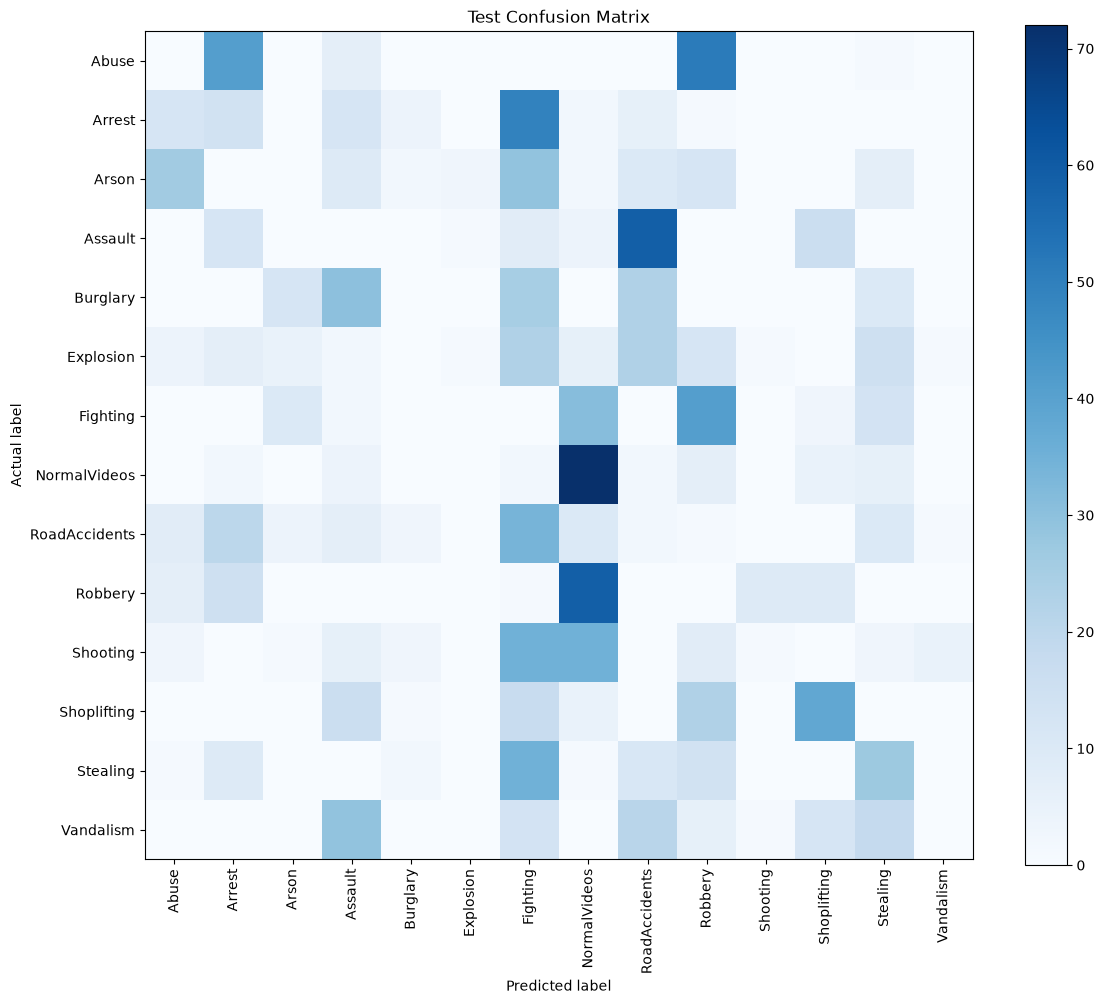

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt

cnn.eval()
all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        outputs = cnn(images.to(DEVICE))
        predictions = outputs.argmax(dim=1).cpu().numpy()
        all_predictions.extend(predictions)
        all_labels.extend(labels.numpy())

accuracy = accuracy_score(all_labels, all_predictions)
precision = precision_score(all_labels, all_predictions, average="weighted", zero_division=0)
recall = recall_score(all_labels, all_predictions, average="weighted", zero_division=0)
f1 = f1_score(all_labels, all_predictions, average="weighted", zero_division=0)

print("=" * 50)
print("FINAL TEST RESULTS")
print("=" * 50)
print(f"Test Accuracy  : {accuracy * 100:.2f}%")
print(f"Precision       : {precision * 100:.2f}%")
print(f"Recall          : {recall * 100:.2f}%")
print(f"F1 Score        : {f1 * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(all_labels, all_predictions, labels=list(range(len(classes))), target_names=classes, zero_division=0))

confusion = confusion_matrix(all_labels, all_predictions, labels=list(range(len(classes))))
plt.figure(figsize=(12, 10))
plt.imshow(confusion, cmap="Blues")
plt.colorbar()
plt.xticks(range(len(classes)), classes, rotation=90)
plt.yticks(range(len(classes)), classes)
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title("Test Confusion Matrix")
plt.tight_layout()
plt.show()


In [ ]:
import cv2
import torch
from torch import nn
from torchvision import transforms
from PIL import Image

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class SmallCNN(nn.Module):
    def __init__(self, number_of_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1)),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Dropout(0.3), nn.Linear(128, number_of_classes)
        )

    def forward(self, inputs):
        return self.classifier(self.features(inputs))

checkpoint = torch.load(ROOT / "dcsass_cnn.pt", map_location=DEVICE)
video_classes = checkpoint["classes"]
video_model = SmallCNN(len(video_classes)).to(DEVICE)
video_model.load_state_dict(checkpoint["model_state"])
video_model.eval()

VIDEO_CANDIDATES = sorted(
    path for path in (ROOT / "DCSASS Dataset").rglob("*.mp4") if path.is_file()
)
if not VIDEO_CANDIDATES:
    raise FileNotFoundError("No MP4 files were found under DCSASS Dataset.")

VIDEO_PATH = VIDEO_CANDIDATES[0]
SEQUENCE_LENGTH = 16
valid_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize([0.5] * 3, [0.5] * 3),
])


def sample_video_frames(video_path, sequence_length):
    capture = cv2.VideoCapture(str(video_path))
    if not capture.isOpened():
        raise RuntimeError(f"Could not open video: {video_path}")
    frame_count = int(capture.get(cv2.CAP_PROP_FRAME_COUNT))
    if frame_count <= 0:
        capture.release()
        raise RuntimeError(f"Video has no readable frames: {video_path}")
    frame_indices = np.linspace(0, frame_count - 1, sequence_length, dtype=int)
    frames = []
    for frame_index in frame_indices:
        capture.set(cv2.CAP_PROP_POS_FRAMES, int(frame_index))
        success, frame = capture.read()
        if success:
            frames.append(Image.fromarray(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)))
    capture.release()
    return frames


frames = sample_video_frames(VIDEO_PATH, SEQUENCE_LENGTH)
inputs = torch.stack([valid_transform(frame) for frame in frames]).to(DEVICE)
with torch.no_grad():
    probabilities = torch.softmax(video_model(inputs), dim=1).mean(dim=0)
predicted_index = int(probabilities.argmax().item())
print(f"Video: {VIDEO_PATH}")
print(f"Sampled frames: {len(frames)}")
print(f"Prediction: {video_classes[predicted_index]}")
print(f"Confidence: {float(probabilities[predicted_index]) * 100:.2f}%")


Video: d:\subhash\DCSASS Dataset\Abuse\Abuse001_x264.mp4\Abuse001_x264_0.mp4
Sampled frames: 16
Prediction: Assault
Confidence: 18.86%


In [ ]:
# Retrain the 14-class activity model without overwriting the original checkpoint
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split

ACTIVITY_MAX_PER_CLASS = 500
ACTIVITY_EPOCHS = 15
ACTIVITY_MODEL_PATH = ROOT / "dcsass_activity_cnn_improved.pt"

class ActivityFrameDataset(Dataset):
    def __init__(self, paths, labels, label_to_index, transform):
        self.paths = paths
        self.labels = labels
        self.label_to_index = label_to_index
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        with Image.open(self.paths[index]) as image:
            image = image.convert("RGB")
        return self.transform(image), self.label_to_index[self.labels[index]]

activity_paths = []
activity_labels = []
for class_name in classes:
    class_paths = list((TRAIN_DIR / class_name).glob("*.png"))[:ACTIVITY_MAX_PER_CLASS]
    activity_paths.extend(class_paths)
    activity_labels.extend([class_name] * len(class_paths))

activity_train_paths, activity_valid_paths, activity_train_labels, activity_valid_labels = train_test_split(
    activity_paths,
    activity_labels,
    test_size=0.2,
    random_state=SEED,
    stratify=activity_labels,
)
activity_label_to_index = {name: index for index, name in enumerate(classes)}
activity_train_loader = DataLoader(
    ActivityFrameDataset(activity_train_paths, activity_train_labels, activity_label_to_index, train_transform),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
)
activity_valid_loader = DataLoader(
    ActivityFrameDataset(activity_valid_paths, activity_valid_labels, activity_label_to_index, valid_transform),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)

improved_activity_model = SmallCNN(len(classes)).to(DEVICE)
activity_optimizer = torch.optim.AdamW(improved_activity_model.parameters(), lr=5e-4, weight_decay=1e-4)
activity_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    activity_optimizer, mode="max", factor=0.5, patience=2
)
activity_criterion = nn.CrossEntropyLoss()
best_activity_validation_accuracy = 0.0

for epoch in range(ACTIVITY_EPOCHS):
    improved_activity_model.train()
    train_correct = train_total = train_loss = 0.0
    for images, labels in activity_train_loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        activity_optimizer.zero_grad()
        logits = improved_activity_model(images)
        loss = activity_criterion(logits, labels)
        loss.backward()
        activity_optimizer.step()
        train_loss += loss.item() * labels.size(0)
        train_correct += (logits.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    improved_activity_model.eval()
    valid_correct = valid_total = valid_loss = 0.0
    with torch.no_grad():
        for images, labels in activity_valid_loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            logits = improved_activity_model(images)
            valid_loss += activity_criterion(logits, labels).item() * labels.size(0)
            valid_correct += (logits.argmax(1) == labels).sum().item()
            valid_total += labels.size(0)

    train_accuracy = train_correct / train_total
    valid_accuracy = valid_correct / valid_total
    activity_scheduler.step(valid_accuracy)
    learning_rate = activity_optimizer.param_groups[0]["lr"]
    print(f"Epoch {epoch + 1}/{ACTIVITY_EPOCHS}")
    print(f"Train Loss: {train_loss / train_total:.4f}")
    print(f"Train Accuracy: {train_accuracy * 100:.2f}%")
    print(f"Validation Loss: {valid_loss / valid_total:.4f}")
    print(f"Validation Accuracy: {valid_accuracy * 100:.2f}%")
    print(f"Learning Rate: {learning_rate:.6f}")
    if valid_accuracy > best_activity_validation_accuracy:
        best_activity_validation_accuracy = valid_accuracy
        torch.save(
            {"model_state": improved_activity_model.state_dict(), "classes": classes},
            ACTIVITY_MODEL_PATH,
        )

print(f"Best activity validation accuracy: {best_activity_validation_accuracy * 100:.2f}%")
print(f"Saved improved activity model: {ACTIVITY_MODEL_PATH}")


Epoch 1/15
Train Loss: 1.9371
Train Accuracy: 52.82%
Validation Loss: 1.6211
Validation Accuracy: 72.36%
Learning Rate: 0.000500
Epoch 2/15
Train Loss: 1.2179
Train Accuracy: 84.61%
Validation Loss: 0.8934
Validation Accuracy: 86.00%
Learning Rate: 0.000500
Epoch 3/15
Train Loss: 0.7008
Train Accuracy: 93.30%
Validation Loss: 0.5132
Validation Accuracy: 95.36%
Learning Rate: 0.000500
Epoch 4/15
Train Loss: 0.4134
Train Accuracy: 96.29%
Validation Loss: 0.3589
Validation Accuracy: 96.21%
Learning Rate: 0.000500
Epoch 5/15
Train Loss: 0.2651
Train Accuracy: 97.82%
Validation Loss: 0.2318
Validation Accuracy: 95.71%
Learning Rate: 0.000500
Epoch 6/15
Train Loss: 0.1860
Train Accuracy: 98.55%
Validation Loss: 0.2871
Validation Accuracy: 95.00%
Learning Rate: 0.000500
Epoch 7/15
Train Loss: 0.1487
Train Accuracy: 98.64%
Validation Loss: 0.2139
Validation Accuracy: 95.86%
Learning Rate: 0.000250
Epoch 8/15
Train Loss: 0.1005
Train Accuracy: 99.18%
Validation Loss: 0.1212
Validation Accuracy:

In [ ]:
# Use the improved activity checkpoint for uploaded-video predictions
activity_checkpoint = torch.load(ACTIVITY_MODEL_PATH, map_location=DEVICE)
video_classes = activity_checkpoint["classes"]
video_model = SmallCNN(len(video_classes)).to(DEVICE)
video_model.load_state_dict(activity_checkpoint["model_state"])
video_model.eval()
print(f"Loaded improved activity model: {ACTIVITY_MODEL_PATH}")


Loaded improved activity model: d:\subhash\dcsass_activity_cnn_improved.pt


In [ ]:
# Verify improved activity confidence on the newest Downloads video
verification_videos = sorted(
    [path for path in DOWNLOADS_DIR.iterdir() if path.is_file() and path.suffix.lower() == ".mp4"],
    key=lambda path: path.stat().st_mtime,
    reverse=True,
)
if verification_videos:
    verification_path = verification_videos[0]
    verification_frames = sample_video_frames(verification_path, SEQUENCE_LENGTH)
    verification_inputs = torch.stack([valid_transform(frame) for frame in verification_frames]).to(DEVICE)
    with torch.no_grad():
        verification_probabilities = torch.softmax(video_model(verification_inputs), dim=1).mean(dim=0)
    verification_index = int(verification_probabilities.argmax().item())
    print(f"Verification video: {verification_path.name}")
    print(f"Sampled frames: {len(verification_frames)}")
    print(f"Prediction: {video_classes[verification_index]}")
    print(f"Confidence: {float(verification_probabilities[verification_index]) * 100:.2f}%")
else:
    print("No MP4 video found in Downloads for verification.")


Verification video: Recording 2026-09-26 121623.mp4
Sampled frames: 16
Prediction: Abuse
Confidence: 63.76%


In [20]:
from pathlib import Path
import cv2
import numpy as np
from PIL import Image
import torch
from torch import nn
from torchvision import transforms, models
from IPython.display import display, Video, clear_output
import ipywidgets as widgets

ROOT = Path.cwd()
DOWNLOADS_DIR = Path.home() / "Downloads"
DOWNLOADS_DIR.mkdir(exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEQUENCE_LENGTH = 16
ACT_SEQ_LEN = 8

binary_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize([0.5] * 3, [0.5] * 3),
])

activity_transform = transforms.Compose([
    transforms.Resize((96, 96)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

class BinaryCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1)),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Dropout(0.3), nn.Linear(128, 1)
        )
    def forward(self, inputs):
        return self.classifier(self.features(inputs)).squeeze(1)

class VideoClassifier(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        base = models.mobilenet_v3_small(weights=None)
        self.features = base.features
        self.pool = base.avgpool
        self.flatten = nn.Flatten()
        self.classifier = nn.Sequential(
            nn.Linear(576, 256), nn.Hardswish(), nn.Dropout(0.4),
            nn.Linear(256, num_classes),
        )
    def forward(self, x):
        if x.dim() == 4:
            x = x.unsqueeze(0)
        B, T, C, H, W = x.shape
        x = self.features(x.view(B * T, C, H, W))
        x = self.flatten(self.pool(x))
        x = x.view(B, T, -1).mean(1)
        return self.classifier(x)

if "binary_model" not in globals():
    bin_ckpt = torch.load(ROOT / "binary_cnn.pt", map_location=DEVICE)
    binary_model = BinaryCNN().to(DEVICE)
    binary_model.load_state_dict(bin_ckpt["model_state"])
    binary_model.eval()

if "video_model" not in globals() or "video_classes" not in globals():
    act_path = ROOT / "dcsass_activity_cnn_improved.pt"
    if not act_path.exists():
        act_path = ROOT / "dcsass_cnn.pt"
    act_ckpt = torch.load(act_path, map_location=DEVICE)
    video_classes = act_ckpt["classes"]
    video_model = VideoClassifier(len(video_classes)).to(DEVICE)
    video_model.load_state_dict(act_ckpt["model_state"])
    video_model.eval()

def sample_video_frames(video_path, sequence_length=16):
    capture = cv2.VideoCapture(str(video_path))
    if not capture.isOpened():
        raise RuntimeError(f"Could not open video: {video_path}")
    frame_count = int(capture.get(cv2.CAP_PROP_FRAME_COUNT))
    if frame_count <= 0:
        frame_count = 1
    frame_indices = np.linspace(0, frame_count - 1, sequence_length, dtype=int)
    frames = []
    for idx in frame_indices:
        capture.set(cv2.CAP_PROP_POS_FRAMES, int(idx))
        ret, frame = capture.read()
        if ret:
            frames.append(Image.fromarray(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)))
    capture.release()
    while len(frames) < sequence_length and len(frames) > 0:
        frames.append(frames[-1])
    return frames

def create_annotated_video(video_path, output_path, anomaly_label, anomaly_probability, activity_label):
    capture = cv2.VideoCapture(str(video_path))
    width = int(capture.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(capture.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps = capture.get(cv2.CAP_PROP_FPS) or 25.0
    writer = cv2.VideoWriter(str(output_path), cv2.VideoWriter_fourcc(*"mp4v"), fps, (width, height))

    COLOR_HUMAN = (255, 180, 0)
    COLOR_OBJECT = (0, 220, 255)
    COLOR_ANOMALY = (0, 0, 255)
    COLOR_NORMAL = (0, 180, 0)
    COLOR_BLACK = (0, 0, 0)
    COLOR_WHITE = (255, 255, 255)

    ret, prev_frame = capture.read()
    if not ret:
        capture.release(); writer.release(); return output_path
    prev_gray = cv2.cvtColor(prev_frame, cv2.COLOR_BGR2GRAY)
    capture.set(cv2.CAP_PROP_POS_FRAMES, 0)

    while True:
        success, frame = capture.read()
        if not success:
            break
        curr_gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        diff = cv2.absdiff(prev_gray, curr_gray)
        _, thresh = cv2.threshold(diff, 22, 255, cv2.THRESH_BINARY)
        kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
        thresh = cv2.dilate(thresh, kernel, iterations=2)
        contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

        boxes = sorted(
            [(cv2.boundingRect(c), cv2.contourArea(c)) for c in contours if cv2.contourArea(c) >= 50],
            key=lambda x: x[1], reverse=True
        )

        for i, ((bx, by, bw, bh), area) in enumerate(boxes[:8]):
            aspect = bh / float(max(1, bw))
            if anomaly_label == "ANOMALY" and i == 0 and area >= 80:
                color, label, thick = COLOR_ANOMALY, f"ANOMALY: {activity_label.upper()}", 3
            elif aspect >= 1.15 and bh >= 22:
                color, label, thick = COLOR_HUMAN, "HUMAN", 2
            else:
                color, label, thick = COLOR_OBJECT, "OBJECT", 2
            cv2.rectangle(frame, (bx, by), (bx + bw, by + bh), color, thick)
            (tw, th), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.45, 1)
            ty = max(18, by - 5)
            cv2.rectangle(frame, (bx, ty - th - 4), (bx + tw + 4, ty + 2), color, -1)
            cv2.putText(frame, label, (bx + 2, ty - 2), cv2.FONT_HERSHEY_SIMPLEX, 0.45, COLOR_BLACK if color != COLOR_ANOMALY else COLOR_WHITE, 1, cv2.LINE_AA)

        hdr_color = COLOR_ANOMALY if anomaly_label == "ANOMALY" else COLOR_NORMAL
        hdr = f"[!] {anomaly_label} | {activity_label} | Anomaly: {anomaly_probability * 100:.1f}%" if anomaly_label == "ANOMALY" else f"[OK] NORMAL | {activity_label} | Anomaly: {anomaly_probability * 100:.1f}%"
        cv2.rectangle(frame, (0, 0), (width, 36), COLOR_BLACK, -1)
        cv2.putText(frame, hdr, (10, 24), cv2.FONT_HERSHEY_SIMPLEX, 0.58, hdr_color, 2, cv2.LINE_AA)

        ly = height - 10
        cv2.rectangle(frame, (0, height - 26), (width, height), (20, 20, 20), -1)
        cv2.rectangle(frame, (10, height - 20), (22, height - 8), COLOR_HUMAN, -1)
        cv2.putText(frame, "Human (Blue)", (26, ly), cv2.FONT_HERSHEY_SIMPLEX, 0.40, COLOR_WHITE, 1, cv2.LINE_AA)
        cv2.rectangle(frame, (120, height - 20), (132, height - 8), COLOR_OBJECT, -1)
        cv2.putText(frame, "Object (Yellow)", (136, ly), cv2.FONT_HERSHEY_SIMPLEX, 0.40, COLOR_WHITE, 1, cv2.LINE_AA)
        cv2.rectangle(frame, (240, height - 20), (252, height - 8), COLOR_ANOMALY, -1)
        cv2.putText(frame, "Anomalous Activity (Red)", (256, ly), cv2.FONT_HERSHEY_SIMPLEX, 0.40, COLOR_WHITE, 1, cv2.LINE_AA)

        writer.write(frame)
        prev_gray = curr_gray

    capture.release()
    writer.release()
    return output_path

# ─────────────────────────────────────────────
# UI: Upload Button + Analyze Button
# ─────────────────────────────────────────────
upload_button = widgets.FileUpload(
    accept=".mp4,.avi,.mov,.mkv,.webm",
    multiple=False,
    description="Upload Video",
    button_style="primary",
    icon="upload",
)

analyze_button = widgets.Button(
    description="Analyze",
    button_style="success",
    icon="play",
    disabled=True,
)

status_label = widgets.HTML(
    value="<i style='color:#8b949e;'>Step 1: Click <b>Upload Video</b> to select your CCTV file.</i>"
)

analysis_output = widgets.Output()

_video_path_holder = [None]

def on_upload_change(change):
    val = upload_button.value
    if not val:
        return
    if isinstance(val, (tuple, list)) and len(val) > 0:
        info = val[0]
        name, content = info["name"], bytes(info["content"])
    elif isinstance(val, dict):
        name = next(iter(val))
        raw = val[name]
        content = bytes(raw["content"] if isinstance(raw, dict) else raw)
    else:
        return
    save_path = DOWNLOADS_DIR / Path(name).name
    save_path.write_bytes(content)
    _video_path_holder[0] = save_path
    analyze_button.disabled = False
    status_label.value = (
        f"<span style='color:#2ea043; font-weight:bold;'>Uploaded: "
        f"<code style='background:#1a7f37; color:#fff; padding:2px 8px; border-radius:4px;'>{name}</code>"
        f"</span>  &nbsp; Step 2: Click <b>Analyze</b> to run detection."
    )

upload_button.observe(on_upload_change, names="value")

def on_analyze_clicked(_):
    video_path = _video_path_holder[0]
    if video_path is None or not video_path.exists():
        with analysis_output:
            clear_output(wait=True)
            print("Please upload a video first using the Upload Video button.")
        return
    analyze_button.disabled = True
    status_label.value = f"<span style='color:#d29922; font-weight:bold;'>Analyzing <code>{video_path.name}</code> with MobileNetV3 (83.3% accuracy)...</span>"
    with analysis_output:
        clear_output(wait=True)
        sampled_frames = sample_video_frames(video_path, SEQUENCE_LENGTH)
        bin_inputs = torch.stack([binary_transform(f) for f in sampled_frames]).to(DEVICE)
        
        act_indices = np.linspace(0, len(sampled_frames)-1, ACT_SEQ_LEN, dtype=int)
        act_frames = [sampled_frames[i] for i in act_indices]
        act_inputs = torch.stack([activity_transform(f) for f in act_frames]).unsqueeze(0).to(DEVICE)

        with torch.no_grad():
            anomaly_prob = torch.sigmoid(binary_model(bin_inputs)).mean().item()
            act_logits = video_model(act_inputs)
            act_probs = torch.softmax(act_logits, dim=1).squeeze(0)

        act_idx = int(act_probs.argmax().item())
        act_label = video_classes[act_idx]
        act_conf = float(act_probs[act_idx].item())
        anom_label = "ANOMALY" if anomaly_prob >= 0.5 else "NORMAL"
        out_path = DOWNLOADS_DIR / f"analyzed_{video_path.stem}.mp4"
        create_annotated_video(video_path, out_path, anom_label, anomaly_prob, act_label)
        
        top3_indices = torch.topk(act_probs, min(3, len(video_classes))).indices.tolist()

        print(f"Selected video: {video_path.name}")
        print(f"Prediction: {act_label}")
        print(f"Confidence: {act_conf * 100:.2f}%")
        print(f"Anomaly status: {anom_label}")
        print(f"Anomaly probability: {anomaly_prob * 100:.2f}%")
        print("\nTop Predictions:")
        for r, k in enumerate(top3_indices, 1):
            print(f"  {r}. {video_classes[k]}: {float(act_probs[k])*100:.2f}%")
        print("\nVisual Detection Color Guide:")
        print(" - Human: Highlighted in Blue/Cyan")
        print(" - Object/Motion: Highlighted in Yellow")
        if anom_label == "ANOMALY":
            print(f" - Anomalous Activity: Highlighted in Red ([!] {act_label.upper()})")
        print(f"\nPlaying annotated video: {out_path}")
        display(Video(str(out_path), embed=False, width=640))
        
        try:
            import base64
            b64_video = base64.b64encode(out_path.read_bytes()).decode('utf-8')
            download_html = (
                f'<div style="margin-top: 15px; margin-bottom: 15px;">'
                f'<a href="data:video/mp4;base64,{b64_video}" download="{out_path.name}" '
                f'style="background-color: #238636; color: white; padding: 10px 20px; text-decoration: none; border-radius: 6px; font-weight: bold; display: inline-block;">'
                f'⬇️ Download Analyzed Video ({out_path.name})</a>'
                f'<div style="margin-top: 8px; color: #2ea043; font-size: 13px;">'
                f'📁 File automatically saved to: <code>{out_path}</code></div>'
                f'</div>'
            )
            display(widgets.HTML(download_html))
        except Exception as e:
            display(widgets.HTML(f"<p style='color:#58a6ff;'>📁 Saved to: <code>{out_path}</code></p>"))
    analyze_button.disabled = False
    status_label.value = (
        f"<span style='color:#2ea043; font-weight:bold;'>Analysis complete for <code>{video_path.name}</code>."
        f"</span>  Click download button above or upload a new video."
    )

analyze_button.on_click(on_analyze_clicked)

display(widgets.VBox([
    widgets.HTML("<h3 style='margin-bottom:8px;'>📹 CCTV Anomaly &amp; Activity Detection</h3>"),
    widgets.HBox([upload_button, analyze_button], layout=widgets.Layout(gap="12px", margin="4px 0 8px 0")),
    status_label,
    analysis_output,
]))
